# 02. Clasificación en Redes Neuronales con TensorFlow

Ahora que hemos visto cómo abordar un problema de regresión en TensorFlow, exploremos cómo podemos enfrentar un problema de clasificación.

Un [problema de clasificación](https://es.wikipedia.org/wiki/Clasificaci%C3%B3n_estad%C3%ADstica) implica predecir si algo pertenece a una categoría u otra.

Por ejemplo, podríamos querer:
* Predecir si una persona tiene o no una enfermedad cardíaca en función de sus parámetros de salud. A esto se le llama **clasificación binaria** ya que solo existen dos opciones.
* Decidir si una fotografía es de comida, de una persona o de un perro. A esto se le denomina **clasificación multiclase** ya que existen más de dos opciones.
* Predecir qué categorías deben asignarse a un artículo de Wikipedia. Esto se conoce como **clasificación multietiqueta** dado que un solo artículo puede tener más de una categoría asignada.

En este cuaderno, trabajaremos a través de varios problemas de clasificación con TensorFlow. Es decir, tomaremos un conjunto de entradas y predeciremos a qué clase pertenece ese conjunto de entradas.

## Qué vamos a cubrir

Específicamente, abordaremos lo siguiente con TensorFlow:
- Arquitectura de un modelo de clasificación
- Formas de entrada y salida
  - `X`: características/datos (entradas)
  - `y`: etiquetas (salidas)
    - "¿A qué clase pertenecen las entradas?"
- Creación de datos personalizados para visualización y ajuste
- Pasos en la modelización para la clasificación binaria y multiclase
  - Creación de un modelo
  - Compilación de un modelo
    - Definición de una función de pérdida
    - Configuración de un optimizador
      - Encontrar la mejor tasa de aprendizaje
    - Creación de métricas de evaluación
  - Ajuste del modelo (hacer que encuentre patrones en nuestros datos)
  - Mejora del modelo
- El poder de la no linealidad
- Evaluación de modelos de clasificación
  - Visualización del modelo ("visualizar, visualizar, visualizar")
  - Observación de las curvas de entrenamiento
  - Comparación de las predicciones con los valores reales (usando nuestras métricas de evaluación)

## Cómo puedes usar este cuaderno

Puedes leer las descripciones y el código (todo debería ejecutarse, excepto las celdas que contienen errores intencionados), pero hay una mejor opción.

Escribe todo el código tú mismo.

Sí, en serio. Crea un nuevo cuaderno y reescribe cada línea por tu cuenta. Examina el código, intenta romperlo, ¿por qué falla?

No es necesario que escribas las descripciones en texto, pero escribir el código tú mismo es una excelente manera de adquirir experiencia práctica.

No te preocupes si cometes errores, todos lo hacemos. La forma de mejorar y cometer menos errores es **escribir más código**.


## Arquitectura típica de una red neuronal de clasificación

La palabra *típica* se utiliza deliberadamente.

Esto se debe a que la arquitectura de una red neuronal de clasificación puede variar enormemente según el problema en el que estés trabajando.

Sin embargo, existen algunos elementos fundamentales que todas las redes neuronales profundas contienen:
* Una capa de entrada.
* Algunas capas ocultas.
* Una capa de salida.

Mucho del resto queda a criterio del analista de datos que crea el modelo.

A continuación se presentan algunos valores estándar que suelen usarse en redes neuronales de clasificación.

| **Hiperparámetro** | **Clasificación binaria** | **Clasificación multiclase** |
| --- | --- | --- |
| Forma de la capa de entrada | Igual al número de características (por ejemplo, 5 para edad, sexo, altura, peso, estado de fumador en la predicción de enfermedades cardíacas) | Igual que en clasificación binaria |
| Capa(s) oculta(s) | Específico al problema, mínimo = 1, máximo = ilimitado | Igual que en clasificación binaria |
| Neuronas por capa oculta | Específico al problema, generalmente de 10 a 100 | Igual que en clasificación binaria |
| Forma de la capa de salida | 1 (una clase u otra) | 1 por clase (por ejemplo, 3 para foto de comida, persona o perro) |
| Activación oculta | Generalmente [ReLU](https://www.kaggle.com/dansbecker/rectified-linear-units-relu-in-deep-learning) (unidad lineal rectificada) | Igual que en clasificación binaria |
| Activación de salida | [Sigmoide](https://es.wikipedia.org/wiki/Funci%C3%B3n_sigmoide) | [Softmax](https://es.wikipedia.org/wiki/Softmax) |
| Función de pérdida | [Entropía cruzada](https://es.wikipedia.org/wiki/Entrop%C3%ADa_cruzada#Funci%C3%B3n_de_p%C3%A9rdida_de_entrop%C3%ADa_cruzada_y_regresi%C3%B3n_log%C3%ADstica) ([`tf.keras.losses.BinaryCrossentropy`](https://www.tensorflow.org/api_docs/python/tf/keras/losses/BinaryCrossentropy) en TensorFlow) | Entropía cruzada ([`tf.keras.losses.CategoricalCrossentropy`](https://www.tensorflow.org/api_docs/python/tf/keras/losses/CategoricalCrossentropy) en TensorFlow) |
| Optimizador | [SGD](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD) (descenso de gradiente estocástico), [Adam](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) | Igual que en clasificación binaria |

Tabla 1: Arquitectura típica de una red de clasificación. Fuente: Adaptado de la página 295 de [Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow Book de Aurélien Géron](https://www.oreilly.com/library/view/hands-on-machine-learning/9781492032632/)

No te preocupes si ahora mismo no entiendes mucho de lo anterior; ganaremos experiencia a medida que avancemos en este cuaderno.

Comencemos importando TensorFlow con el alias común `tf`. Para este cuaderno, asegúrate de estar utilizando la versión 2.x+.


In [1]:
import tensorflow as tf
from matplotlib import pyplot as plt

print(tf.__version__)

import datetime
print(f"última ejecución del notebook: {datetime.datetime.now()}")

I0000 00:00:1794843647.268437    9384 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794843647.626890    9384 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794843648.636531    9384 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


2.21.0
última ejecución del notebook: 2026-11-16 16:40:49.409656


## Creación de datos para visualizar y ajustar

Vamos a crear algunos datos de clasificación propios.

> 🔑 **Nota:** Es una práctica común trabajar con un conjunto de datos de prueba (o sencillo) para asegurarte de que tú y el modelo que construyes funcionan correctamente antes de pasar al problema real. Trátalo como un experimento de ensayo previo al experimento real.

Dado que la clasificación consiste en predecir si algo es una cosa o la otra, crearemos algunos datos que reflejen esa idea.

Para hacerlo, utilizaremos la función [`make_circles()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_circles.html#sklearn.datasets.make_circles) de Scikit-Learn.




In [315]:
from sklearn.datasets import make_circles, make_moons

#utiliza la función make_circles para crear 1000 muestras, guarda las muestras en X y las etiquetas en y
X, y = make_moons(1000, noise=0.15, random_state=42)

ahora que hemos creado algunos datos, veamos las características (`X`) y las etiquetas (`y`).


In [116]:
#examina X
X

array([[ 0.68201001,  0.32271087],
       [-0.62339939,  0.24585545],
       [-0.90219262,  0.4653438 ],
       ...,
       [-0.08488159, -0.90673993],
       [ 0.61361939, -0.92163318],
       [ 0.26520621,  0.98503501]], shape=(1000, 2))

In [117]:
# examina las 10 primeras etiquetas
y[:10]

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 0])



> 🔑 **Nota:** Un paso importante al iniciar cualquier tipo de proyecto de aprendizaje automático es [conocer a fondo los datos](https://karpathy.github.io/2019/04/25/recipe/). Una de las mejores maneras de lograr esto es visualizar los datos con los que estás trabajando tanto como sea posible. 

Usaremos para ello un dataframe de Pandas

In [316]:
# Cargamos en un dataframe nuestros datos y examinamos la pinta que tiene
import pandas as pd
circulos = pd.DataFrame({"X0":X[:, 0], "X1":X[:, 1], "label":y})
circulos.head()

,X0,X1,label
0,-0.081568,0.482211,1
1,1.087333,-0.381159,1
2,0.831725,-0.133135,1
3,0.200339,-0.500300,1
4,-0.824953,0.539526,0


¿Qué tipo de etiquetas tenemos?

In [119]:
# Miramos las diferentes etiquetas
circulos.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

Muy bien, parece que estamos tratando con un problema de **clasificación binaria**. Es binario porque solo hay dos etiquetas (0 o 1).

Si hubiera más opciones de etiquetas (por ejemplo, 0, 1, 2, 3 o 4), se llamaría **clasificación multiclase**.

Llevemos nuestra visualización un paso más allá y visualizamos nuestros datos.


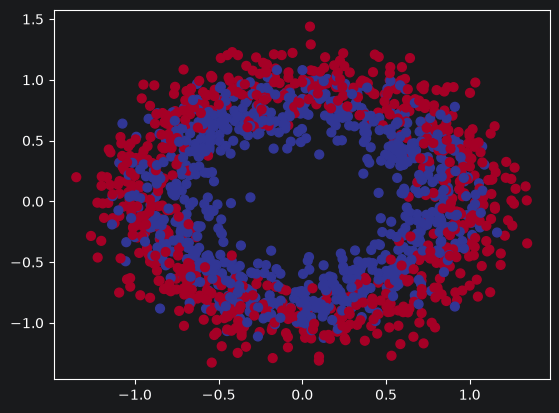

In [212]:
#imprime las muestras con matplotlib. Utiliza para el eje x la columna 0 X[:,0] y para el eje y la columna 1 X[:,1].
# para los colores utiliza (c=y) y con un mapa de color cmap=plt.cm.RdYlBu
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
plt.show()


¡Genial! A partir del gráfico, ¿puedes adivinar qué tipo de modelo podríamos querer construir?

¿Qué te parece si intentamos construir uno que clasifique los puntos azules o rojos? Es decir, un modelo que sea capaz de distinguir entre puntos azules y rojos.

> 🛠 **Práctica:** Antes de avanzar, podrías dedicar unos minutos a experimentar con el [TensorFlow Playground](https://playground.tensorflow.org/#activation=relu&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=2,2&seed=0.93799&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularization_hide=true&regularizationRate_hide=true&batchSize_hide=true). Intenta ajustar los diferentes hiperparámetros que ves y haz clic en "play" para observar cómo se entrena una red neuronal. Creo que encontrarás que los datos son muy similares a los que acabamos de crear.


## Capas de entrada y salida

Vamos a explorar qué tipo de formas tenemos



In [11]:
# Comprobar formas y longitud de los vectores
X.shape

(1000, 2)

In [12]:
y.shape

(1000,)

In [13]:
# Examinar la primera muestra y su etiqueta
X[0], y[0]

(array([0.75424625, 0.23148074]), np.int64(1))

Es decir, tenemos dos caracteristicas X que llevan a un único valor y

Esto significa que nuestra red neuronal tendrá que aceptar un tensor de dos dimensiones y producir un tensor con una dimensión


## Pasos en la modelización

Ahora que sabemos qué datos tenemos, así como las formas de entrada y salida, veamos cómo construiríamos una red neuronal para modelarlo.

En TensorFlow, normalmente hay 3 pasos fundamentales para crear y entrenar un modelo.

1. **Crear un modelo** - ensamblar las capas de una red neuronal manualmente (usando el [API funcional](https://www.tensorflow.org/guide/keras/functional) o el [API secuencial](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential)) o importar un modelo previamente construido (conocido como aprendizaje por transferencia).
2. **Compilar un modelo** - definir cómo se debe medir el rendimiento del modelo (pérdida/métricas) y cómo debe mejorar (optimizador).
3. **Ajustar un modelo** - permitir que el modelo intente encontrar patrones en los datos (cómo `X` se convierte en `y`).

Veamos estos pasos en acción usando el API secuencial para construir un modelo para nuestros datos de regresión. Luego analizaremos cada uno de ellos.


In [18]:
#creamos nuestro primer modelo (uno muy sencillo)
tf.random.set_seed(42)

# 1. Crear el modelo usando el api secuencial
model_1 = tf.keras.Sequential([
  tf.keras.layers.Dense(1)
])

# 2. Compilar el modelo
model_1.compile(loss=tf.keras.losses.BinaryCrossentropy(), # Binaria, porque estamos trabajando con clases 0 y 1
                optimizer=tf.keras.optimizers.SGD(),
                metrics=['accuracy'])

# 3. Entrenar el modelo
model_1.fit(X, y, epochs=5)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.4650 - loss: 5.1128
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step - accuracy: 0.4820 - loss: 3.8798
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 660us/step - accuracy: 0.4980 - loss: 0.7964
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 638us/step - accuracy: 0.4920 - loss: 0.7202
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step - accuracy: 0.4960 - loss: 0.7033


Al observar la métrica de precisión, nuestro modelo tiene un rendimiento deficiente (50% de precisión en un problema de clasificación binaria equivale a adivinar), pero ¿qué pasaría si lo entrenamos por más tiempo?


In [19]:
# Entrenar más tiempo
model_1.fit(X, y, epochs=200, verbose=0) # verbose=0 para no mostrar tanto proceso
model_1.evaluate(X, y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 645us/step - accuracy: 0.4730 - loss: 0.6933


[0.6932879686355591, 0.4729999899864197]

Incluso después de 200 pases de los datos, sigue funcionando como si estuviera adivinando (50%).
¿Qué pasaría si añadimos una capa extra y entrenamos por un poco más de tiempo?


In [27]:
#copia el modelo anterior y añade una capa extra de una neurona
model_2 = tf.keras.Sequential([
    tf.keras.layers.Dense(1), #capa extra
    tf.keras.layers.Dense(1)
])

model_2.compile(loss=tf.keras.losses.BinaryCrossentropy(), optimizer='sgd', metrics=['accuracy'])

model_2.fit(X,y,epochs=100, verbose=0)

In [49]:
# evalua el model_2
model_2.evaluate(X,y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 681us/step - accuracy: 0.5000 - loss: 7.9712


[7.971191883087158, 0.5]

Todavía no mejora, recordemos cómo mejorar un modelo:

## Formas comunes de mejorar un modelo:

- **Añadir capas**
- **Incrementar el número de unidades ocultas**
- **Cambiar las funciones de activación**
- **Cambiar la función de optimización**
- **Cambiar la tasa de aprendizaje** (porque puedes alterar cada una de las capas, son hiperparámetros)
- **Entrenar con más datos**
- **Entrenar por más tiempo** (más épocas)


In [52]:
# crea otro modelo model_3, esta vez añade dos capas (una de 100 neuronas y otra de 10) y cambiar el optimizador (Adam)
# entrena 100 épocas
model_3 = tf.keras.Sequential([
    tf.keras.layers.Dense(100),
    tf.keras.layers.Dense(10),
    tf.keras.layers.Dense(1)
])

model_3.compile(loss=tf.keras.losses.BinaryCrossentropy(), optimizer='adam', metrics=['accuracy'])

model_3.fit(X,y,epochs=100, verbose=0)


In [56]:
model_3.evaluate(X,y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 596us/step - accuracy: 0.4870 - loss: 0.6956


[0.6956241130828857, 0.4869999885559082]

¡Aún así!

Hemos intentado algunos trucos, pero nuestro modelo no está rindiendo mejor que si estuviera adivinando.

Hagamos algunas visualizaciones para ver qué está sucediendo.

> 🔑 **Nota:** Siempre que tu modelo se comporte de forma extraña o haya algo en tus datos que no entiendas del todo, recuerda estas tres palabras: **visualizar, visualizar, visualizar**. Inspecciona tus datos, inspecciona tu modelo, inspecciona las predicciones de tu modelo.

Para visualizar las predicciones de nuestro modelo, vamos a crear una función `plot_decision_boundary()` que:

* Recibe un modelo entrenado, características (`X`) y etiquetas (`y`).
* Crea una [malla de valores](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html) a partir de los diferentes valores de `X`.
* Realiza predicciones en toda la malla.
* Grafica las predicciones así como una línea entre las diferentes zonas (donde cae cada clase única).

Si esto suena confuso, veámoslo en el código y luego observemos el resultado.

> 🔑 **Nota:** Si alguna vez tienes dudas sobre lo que hace una función, intenta desglosarla y escribirla línea por línea para entender su funcionamiento. Divídela en partes pequeñas y observa lo que devuelve cada parte.


In [62]:
import numpy as np

def plot_decision_boundary(model, X, y):
  """
  Plots the decision boundary created by a model predicting on X.
  This function has been adapted from two phenomenal resources:
   1. CS231n - https://cs231n.github.io/neural-networks-case-study/
   2. Made with ML basics - https://github.com/GokuMohandas/MadeWithML/blob/main/notebooks/08_Neural_Networks.ipynb
  """
  # Define the axis boundaries of the plot and create a meshgrid
  x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
  y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
  xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                       np.linspace(y_min, y_max, 100))

  # Create X values (we're going to predict on all of these)
  x_in = np.c_[xx.ravel(), yy.ravel()] # stack 2D arrays together: https://numpy.org/devdocs/reference/generated/numpy.c_.html

  # Make predictions using the trained model
  y_pred = model.predict(x_in)

  # Check for multi-class
  if model.output_shape[-1] > 1: # checks the final dimension of the model's output shape, if this is > (greater than) 1, it's multi-class
    # We have to reshape our predictions to get them ready for plotting
    y_pred = np.argmax(y_pred, axis=1).reshape(xx.shape)
  else:
    y_pred = np.round(np.max(y_pred, axis=1)).reshape(xx.shape)

  # Plot decision boundary
  plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.3)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

Ahora que tenemos una función para graficar la frontera de decisión de nuestro modelo (el punto de separación que establece entre los puntos rojos y azules), probémosla.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 234us/step


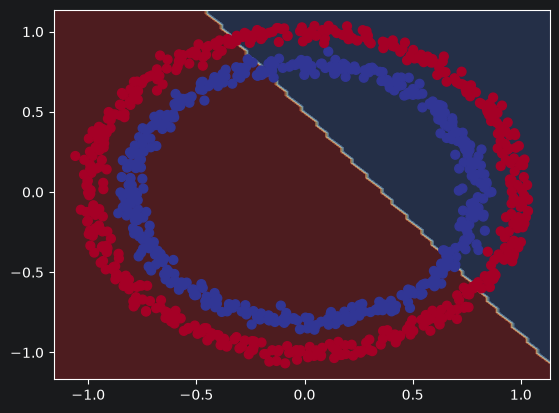

In [63]:
# imprime la frontera del modelo 3
plot_decision_boundary(model_3, X, y)

Parece que nuestro modelo está intentando trazar una línea recta a través de los datos.

¿Qué tiene de malo hacer esto?

El problema principal es que nuestros datos no se pueden separar con una línea recta.


## Introduciendo la "No linealidad"

Hemos visto que nuestra red neuronal puede modelar líneas rectas. ¿Y qué hay de las líneas no rectas?

Si queremos modelar nuestros datos de clasificación (los círculos rojos y azules), vamos a necesitar algo de tipo polinomio.

> 🔨 **Práctica:** Antes de pasar a los siguientes pasos, te sugiero que experimentes con el [TensorFlow Playground](https://playground.tensorflow.org/#activation=linear&batchSize=1&dataset=circle&regDataset=reg-plane&learningRate=0.01&regularizationRate=0&noise=0&networkShape=1&seed=0.09561&showTestData=false&discretize=false&percTrainData=70&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularizationRate_hide=true&discretize_hide=true&regularization_hide=true&dataset_hide=true&noise_hide=true&batchSize_hide=true) (observa qué tienen en común los datos con nuestros propios datos de clasificación). En particular, explora la pestaña que dice "activation". Una vez que termines, vuelve.

¿Probaste las opciones de activación? Si es así, ¿qué descubriste?

Juega con ella en [TensorFlow Playground](https://playground.tensorflow.org/#activation=linear&batchSize=1&dataset=circle&regDataset=reg-plane&learningRate=0.01&regularizationRate=0&noise=0&networkShape=1&seed=0.09561&showTestData=false&discretize=false&percTrainData=70&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZ


In [70]:
#creamos el modelo 4, esta vez le añadimos el parámetro de activación
tf.random.set_seed(42)

model_4 = tf.keras.Sequential([
  tf.keras.layers.Dense(1, activation=tf.keras.activations.linear), # 1 capa oculta con activación lineal
  tf.keras.layers.Dense(1) # capa de salida
])

model_4.compile(loss=tf.keras.losses.binary_crossentropy,
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
                metrics=["accuracy"])

history = model_4.fit(X, y, epochs=100)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 830us/step - accuracy: 0.4790 - loss: 5.8865
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 857us/step - accuracy: 0.4790 - loss: 5.8326
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4780 - loss: 5.8147 
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 669us/step - accuracy: 0.4770 - loss: 5.8065
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 706us/step - accuracy: 0.4770 - loss: 5.8041
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.4770 - loss: 5.8009
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - accuracy: 0.4770 - loss: 5.7989
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - accuracy: 0.4770 - loss: 5.7973
Epoch 9/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step - accuracy: 0.4770 - loss: 5.7960
Epoch 10/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 669us/step - accuracy: 0.4770 - loss: 5.7949
Epoch 11/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - accuracy: 0.4770 - loss: 5.7841
Epoch 12/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s

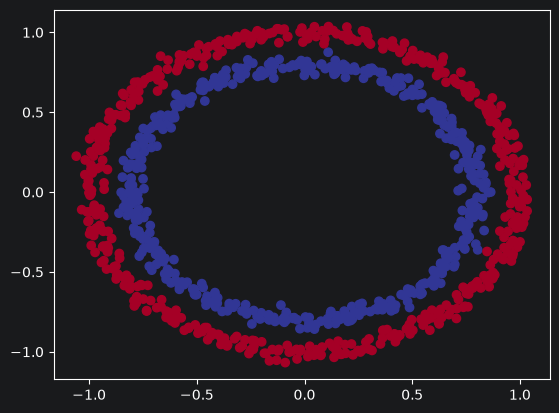

In [68]:
# recordemos la pinta de nuestros datos
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu);

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 239us/step


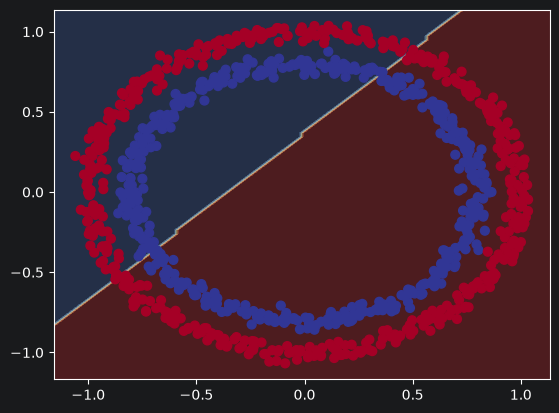

In [69]:
plot_decision_boundary(model_4, X, y)

cambiamos a la activación seleccionando 'relu'

In [95]:
# crea model_5 para cambiar la activación de la primera capa y poner tf.keras.activations.relu
tf.random.set_seed(42)

model_5 = tf.keras.Sequential([
  tf.keras.layers.Dense(1, activation=tf.keras.activations.relu), # 1 capa oculta con activación lineal
  tf.keras.layers.Dense(1) # capa de salida
])

model_5.compile(loss=tf.keras.losses.binary_crossentropy,
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                metrics=["accuracy"])

history = model_5.fit(X, y, epochs=100)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 937us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 731us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 727us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 9/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 10/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 11/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 732us/step - accuracy: 0.5000 - loss: 8.0590
Epoch 12/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0

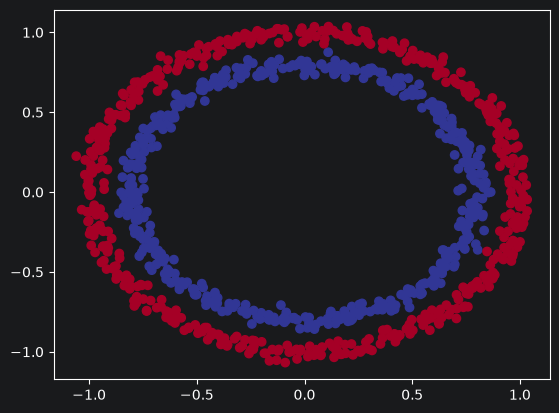

In [96]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step


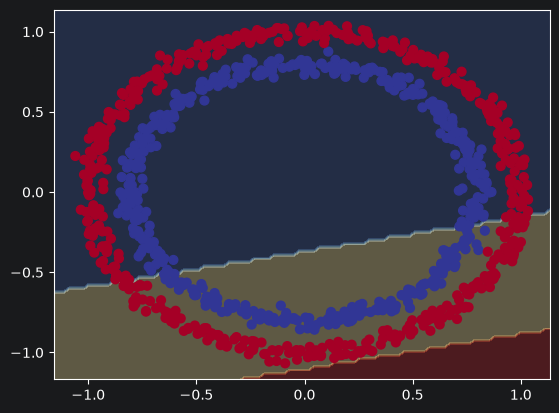

In [97]:
plot_decision_boundary(model_5, X, y)

Todavía no aprende...
 vamos a introducir 2 capas con activación Relu: [ReLU](https://www.tensorflow.org/api_docs/python/tf/keras/activations/relu), (abreviatura de [rectified linear unit](https://machinelearningmastery.com/rectified-linear-activation-function-for-deep-learning-neural-networks/)), activación en la primera capa, cuatro unidades por capa

Para verlo en acción: [TensorFlow Playground demo](https://playground.tensorflow.org/#activation=relu&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.001&regularizationRate=0&noise=0&networkShape=4,4&seed=0.93799&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularization_hide=true&regularizationRate_hide=true&batchSize_hide=true&dataset_hide=true).


In [91]:
# reproduzcamos el ejemplo que hemos hecho con el playground
# crea un model_6 para añadir 2 capas ocultas de 4 neuronas con activación ReLU
tf.random.set_seed(42)

model_6 = tf.keras.Sequential([
  tf.keras.layers.Dense(4, activation=tf.keras.activations.relu), # 1 capa oculta con activación lineal
  tf.keras.layers.Dense(2, activation=tf.keras.activations.relu),
  tf.keras.layers.Dense(2, activation=tf.keras.activations.relu),
  tf.keras.layers.Dense(1, activation=tf.keras.activations.sigmoid) # capa de salida
])

model_6.compile(loss=tf.keras.losses.binary_crossentropy,
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                metrics=["accuracy"])

history = model_6.fit(X, y, epochs=100)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 895us/step - accuracy: 0.5000 - loss: 0.6903 
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 846us/step - accuracy: 0.5060 - loss: 0.6896
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.5090 - loss: 0.6891
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 705us/step - accuracy: 0.5100 - loss: 0.6886
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step - accuracy: 0.5150 - loss: 0.6881
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - accuracy: 0.5170 - loss: 0.6876
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 718us/step - accuracy: 0.5200 - loss: 0.6869
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 720us/step - accuracy: 0.5200 - loss: 0.6861
Epoch 9/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - accuracy: 0.5200 - loss: 0.6853
Epoch 10/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step - accuracy: 0.5210 - loss: 0.6842
Epoch 11/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 718us/step - accuracy: 0.5250 - loss: 0.6831
Epoch 12/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 

In [92]:
# evalua el modelo model_6
model_6.evaluate(X,y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step - accuracy: 0.9770 - loss: 0.1722


[0.1721697896718979, 0.9769999980926514]

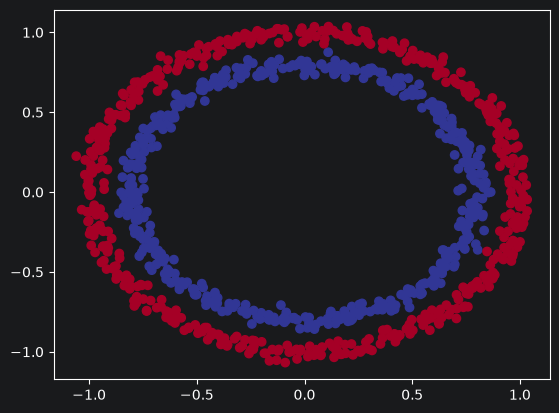

In [93]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

Bueno, algo mejor, veamos los límites de la decisión

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step


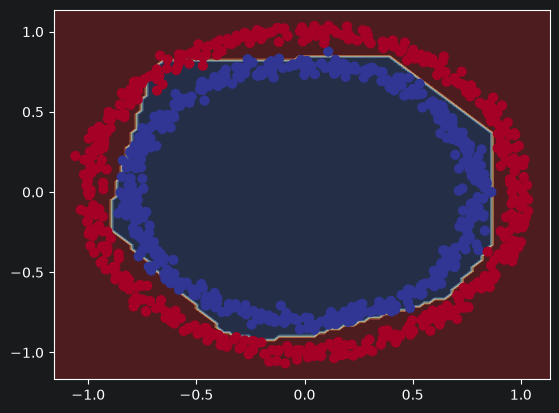

In [94]:
# examina los límites de decisión de model_6
plot_decision_boundary(model_6, X,y)

Vamos a cambiar también la capa de salida activándola con una sigmoide

In [320]:
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(5, activation=tf.keras.activations.relu),
    tf.keras.layers.Dense(3, activation=tf.keras.activations.relu),
    tf.keras.layers.Dense(3, activation=tf.keras.activations.relu),
    tf.keras.layers.Dense(1, activation=tf.keras.activations.sigmoid)
])

model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=350, verbose=0)

In [321]:
model.evaluate(X,y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 706us/step - accuracy: 0.9950 - loss: 0.0272


[0.02715199440717697, 0.9950000047683716]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 293us/step


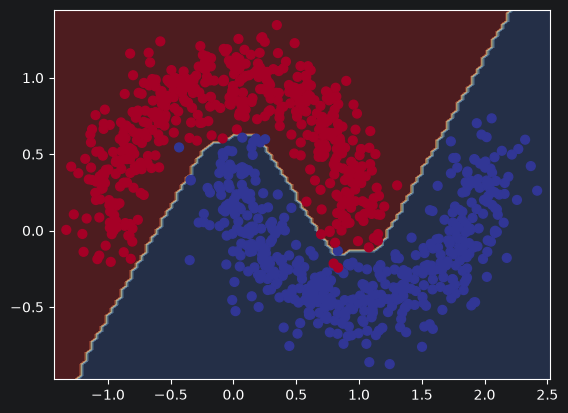

In [322]:
plot_decision_boundary(model, X, y)

In [314]:
model.summary()

Model: "sequential_105"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_353 (Dense)               │ (None, 5)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_354 (Dense)               │ (None, 3)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_355 (Dense)               │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_356 (Dense)               │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 149 (600.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 100 (404.00 B)

In [ ]:
# crea un model_7 clonico de model_6 pero cambia la activación en la capa de salida a sigmoide 
# tf.keras.activations.sigmoid


In [ ]:
# evalua el model_7


Increible!!, un acierto del 99%!

In [ ]:
# examina los límites de model_7


¡Genial! Parece que nuestro modelo está separando casi perfectamente (salvo algunos ejemplos) los dos círculos.

> 🔑 **Nota:** La combinación de **funciones lineales (líneas rectas) y no lineales (líneas no rectas)** es uno de los fundamentos clave de las redes neuronales.
Piensalo de esta manera: Si te diera una cantidad ilimitada de líneas rectas y curvas, ¿qué tipo de patrones podrías dibujar?
Eso es, en esencia, lo que hacen las redes neuronales para encontrar patrones en los datos.

> 🤔 **Pregunta:** ¿Qué problema tienen las predicciones que hemos hecho? ¿Realmente estamos evaluando correctamente nuestro modelo aquí? 
> ¿en qué datos entrenó el modelo y sobre qué datos hicimos las predicciones?


Para obtener una intuición sobre las funciones de activación que hemos usado, vamos a crearlas y luego a probarlas en algunos datos de ejemplo.


In [ ]:
# Creamos un tensor 
A = tf.cast(tf.range(-10, 10), tf.float32)
A

In [ ]:
# visualizamos el tensor
plt.plot(A);

Creamos la función `sigmoid` [sigmoid function](https://en.wikipedia.org/wiki/Sigmoid_function) y vemos qué efecto tiene sobre nuestros datos
 También se puede usar: [`tf.keras.activations.sigmoid`](https://www.tensorflow.org/api_docs/python/tf/keras/activations/sigmoid).

In [ ]:
# Sigmoid - https://www.tensorflow.org/api_docs/python/tf/keras/activations/sigmoid
def sigmoid(x):
  return 1 / (1 + tf.exp(-x))

# aplicamos la sigmoide sobre nuestro tensor
sigmoid(A)

In [ ]:
# visualizamos el efecto
plt.plot(sigmoid(A));

Una curva!

qué pinta tiene la ReLU [ReLU function](https://machinelearningmastery.com/rectified-linear-activation-function-for-deep-learning-neural-networks/#:~:text=The%20rectified%20linear%20activation%20function,otherwise%2C%20it%20will%20output%20zero.) (ReLU cambia a 0 todos los negativos y los positivos los mantiene)

In [ ]:
# ReLU - https://www.tensorflow.org/api_docs/python/tf/keras/activations/relu
def relu(x):
  return tf.maximum(0, x)

relu(A)

In [ ]:
# Plot
plt.plot(relu(A));

Una línea partida (no recta)!

y la función linear? [linear activation function](https://www.tensorflow.org/api_docs/python/tf/keras/activations/linear)?

In [ ]:
# Linear - https://www.tensorflow.org/api_docs/python/tf/keras/activations/linear (retorna la entrada sin modificar...)
tf.keras.activations.linear(A)

In [ ]:
# Se cambia algo en la activación?
A == tf.keras.activations.linear(A)



> 📖  **Recurso:** Echa un ojo a este artículo para ver más funciones de activación [machine learning cheatsheet page](https://ml-cheatsheet.readthedocs.io/en/latest/activation_functions.html#) 

## Evaluación y mejora de nuestro modelo de clasificación

Si respondiste la pregunta anterior, es posible que hayas notado en qué nos hemos estado equivocando.

Hemos estado evaluando nuestro modelo en los mismos datos con los que fue entrenado.

Un mejor enfoque sería dividir nuestros datos en conjuntos de entrenamiento, validación (opcional) y prueba.

Una vez hecho esto, entrenaremos nuestro modelo en el conjunto de entrenamiento (para que aprenda patrones en los datos) y luego evaluaremos qué tan bien aprendió esos patrones usándolo para predecir valores en el conjunto de prueba.

Hagámoslo.


In [ ]:
# ¿Cuantos ejemplos tenemos en nuestro dataset?
len(X)

In [ ]:
# Divide los datos entre train y test (80% de los datos al train, 20% al test) 
# llámalos X_train, X_test, y_train, y_test


Entrenamos sólo sobre datos de train

In [ ]:
# crea un model_8 clon de model 7 pero cambiando el learning_rate a 0.01
# entrenalo sólo con X_train, y_train

In [ ]:
# evalúalo sobre X_test,y_test
# quédate con el loss y el accuracy que devuelve el método evaluate y muéstralos

98% en test!! Muy bien!


In [ ]:
# en matplotlib, con subplots, visualiza los límites para test y train
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_8, X=X_train, y=y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_8, X=X_test, y=y_test)
plt.show()

### Visualizar las curvas de pérdida

Observando los gráficos anteriores, podemos ver que las salidas de nuestro modelo son muy buenas.

Pero, ¿cómo fue el rendimiento de nuestro modelo mientras estaba aprendiendo?

Es decir, ¿cómo cambió el rendimiento cada vez que el modelo tuvo la oportunidad de revisar los datos (una vez por cada época)?

Para averiguarlo, podemos revisar las **curvas de pérdida** (también conocidas como **curvas de aprendizaje**).

Quizás notaste que hemos estado usando la variable `history` al llamar a la función `fit()` en un modelo ([`fit()` devuelve un objeto `History`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit)).

Aquí es donde obtendremos la información sobre el rendimiento de nuestro modelo mientras aprende.

Veamos cómo podríamos usarla.


In [ ]:
# Se puede acceder a la información del objeto history con el atributo history
pd.DataFrame(history.history)

¿Qué pinta tiene?

In [ ]:
pd.DataFrame(history.history).plot()
plt.title("Curva de entrenamiento de model_8")

Fenomenal! Este es el gráfico ideal que buscamos al tratar con un problema de clasificación: la pérdida disminuye y la precisión aumenta.

> 🔑 **Nota:** Para muchos problemas, que la función de pérdida disminuya significa que el modelo está mejorando (las predicciones que realiza se acercan más a las etiquetas verdaderas).


### Encontrando la mejor tasa de aprendizaje

Además de la propia arquitectura (las capas, el número de neuronas, las activaciones, etc.), el hiperparámetro más importante que puedes ajustar para tus modelos de redes neuronales es la **tasa de aprendizaje**.

En `model_8` vimos cómo reducimos la tasa de aprendizaje del optimizador Adam desde su valor predeterminado de `0.001` a `0.01`.

Y quizás te estés preguntando por qué hicimos esto.

Podemos decirlo de esta manera: fue una suposición afortunada.

Simplemente decidí probar una tasa de aprendizaje más baja y ver cómo respondía el modelo.

Ahora puedes estar pensando, "¿En serio? ¿Se puede hacer eso?"

Y la respuesta es sí. Puedes cambiar cualquiera de los hiperparámetros de tus redes neuronales.

Con práctica, comenzarás a ver qué tipo de hiperparámetros funcionan y cuáles no.

Esto es algo importante de entender sobre el aprendizaje automático y el aprendizaje profundo en general. Es muy experimental. Construyes un modelo y lo evalúas, luego ajustas el modelo y vuelves a evaluarlo.

Dicho esto, quiero introducirte un truco que te ayudará a encontrar la tasa de aprendizaje óptima (al menos para comenzar el entrenamiento) para tus modelos en adelante.

Para hacerlo, vamos a usar lo siguiente:
* Un [**callback** de tasa de aprendizaje](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/LearningRateScheduler).
   * Puedes pensar en un callback como una funcionalidad adicional que puedes agregar a tu modelo *mientras* está entrenando.
* Otro modelo (podríamos usar el mismo que antes, pero estamos practicando construir modelos aquí).
* Un gráfico modificado de curvas de pérdida.

Revisaremos cada uno con código, luego explicaremos qué está sucediendo.

> 🔑 **Nota:** Los hiperparámetros predeterminados de muchos componentes de redes neuronales en TensorFlow están configurados de forma que generalmente funcionan bien desde el inicio (por ejemplo, la configuración predeterminada del [optimizador Adam](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) puede obtener buenos resultados en muchos conjuntos de datos). Por lo tanto, es una buena idea probar primero con los valores predeterminados y luego ajustarlos según sea necesario.


In [ ]:
# añade un callback LearningRateScheduler para incrementar el learning rate en cada época 
tf.random.set_seed(42)

# igual que model_8
model_9 = tf.keras.Sequential([
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(1, activation="sigmoid")
])


model_9.compile(loss="binary_crossentropy", # tb podemos usar cadenas
              optimizer="Adam", # igual que tf.keras.optimizers.Adam() pero con los parámetros por defecto
              metrics=["accuracy"])

# Crear un callback planificador de learning rate
# Recorre un conjunto de learning rates desde 1e-4
# , incrementando en 10**(epoch/20) cada época
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(lambda epoch: 1e-4 * 10**(epoch/20)) 


# Entrenar el modelo (pasando el callback del planificador)
history = model_9.fit(X_train,
                      y_train,
                      epochs=100,
                      callbacks=[lr_scheduler])

veamos la history del entrenamiento

In [ ]:
pd.DataFrame(history.history).plot(figsize=(10,7), xlabel="epochs");

Como puedes ver, la tasa de aprendizaje aumenta exponencialmente a medida que aumenta el número de épocas.

Y puedes observar que la precisión del modelo sube (y la pérdida disminuye) en un punto específico cuando la tasa de aprendizaje aumenta lentamente.

Para identificar dónde se encuentra este punto de inflexión, podemos graficar la pérdida frente a la tasa de aprendizaje en escala logarítmica.

In [ ]:
# Imprimir la tasa de aprendizaje vs la pérdida (loss)
lrs = 1e-4 * (10 ** (np.arange(100)/20))
plt.figure(figsize=(10, 7))
plt.semilogx(lrs, history.history["loss"]) 
plt.xlabel("Learning Rate")
plt.ylabel("Loss")
plt.title("Learning rate vs. loss");

Para determinar el valor ideal de la tasa de aprendizaje (al menos el valor ideal para *comenzar* el entrenamiento de nuestro modelo), la regla general es tomar el valor de la tasa de aprendizaje en el punto donde la pérdida aún está disminuyendo, pero no se ha aplanado completamente (generalmente alrededor de 10 veces menor que el mínimo de la curva).

En este caso, nuestra tasa de aprendizaje ideal se encuentra entre `0.01` ($10^{-2}$) y `0.02`.

![encontrar la tasa de aprendizaje ideal graficando tasa de aprendizaje vs. pérdida](https://fp.cloud.riberadeltajo.es/imagenes_cursos/lr_ideal.png)

*La tasa de aprendizaje ideal al inicio del entrenamiento del modelo se encuentra en algún punto justo antes de que la curva de pérdida alcance su mínimo (un valor donde la pérdida aún está disminuyendo).*


In [ ]:
# lr típicos

10**0, 10**-1, 10**-2, 10**-3, 1e-4

Now we've estimated the ideal learning rate (we'll use `0.02`) for our model, let's refit it.

In [ ]:
#entremos con lr=0.02
tf.random.set_seed(42)


model_10 = tf.keras.Sequential([
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(1, activation="sigmoid")
])


model_10.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.02), 
                metrics=["accuracy"])

history = model_10.fit(X_train, y_train, epochs=20)

espectacular! Con un lr de (`0.02` en lugar de `0.01`) alcanzamos una tasa de acierto mejor en menos épocas

> 🛠 **Práctica:** Ahora que has visto un ejemplo de lo que puede ocurrir al cambiar la tasa de aprendizaje, intenta cambiar el valor de la tasa de aprendizaje en el [TensorFlow Playground](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.03154&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularization_hide=true&regularizationRate_hide=true&problem_hide=true) y observa qué sucede. ¿Qué pasa si la aumentas? ¿Qué pasa si la disminuyes?




In [ ]:
# evaluamos...
model_10.evaluate(X_test, y_test)

Veamos las predicciones

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_10, X=X_train, y=y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_10, X=X_test, y=y_test)
plt.show()

Y como podemos ver, casi perfecto nuevamente.

Este es el tipo de experimentos que realizarás con frecuencia al construir tus propios modelos.

Comienza con la configuración predeterminada y observa cómo se comportan en tus datos.

Y si no funcionan tan bien como esperabas, mejóralos.

Veamos algunas formas adicionales de evaluar nuestros modelos de clasificación.


### Más métodos de evaluación de clasificación

Además de las visualizaciones que hemos estado haciendo, existen varias métricas de evaluación que podemos utilizar para evaluar nuestros modelos de clasificación.

| **Nombre de la métrica/Método de evaluación**                                                  | **Definición** | **Código** |
|------------------------------------------------------------------------------------------------| --- | --- |
| Exactitud (Accuracy)                                                                           | De cada 100 predicciones, ¿cuántas acierta tu modelo? Por ejemplo, una exactitud del 95% significa que acierta 95 de 100 predicciones. | [`sklearn.metrics.accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) o [`tf.keras.metrics.Accuracy()`](tensorflow.org/api_docs/python/tf/keras/metrics/Accuracy) |
| Precisión (Precision)                                                                          | Proporción de verdaderos positivos sobre el número total de muestras. Mayor precisión reduce los falsos positivos (el modelo predice 1 cuando debería haber sido 0). | [`sklearn.metrics.precision_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html) o [`tf.keras.metrics.Precision()`](tensorflow.org/api_docs/python/tf/keras/metrics/Precision) |
| Sensibilidad (Recall)                                                                          | Proporción de verdaderos positivos sobre el número total de verdaderos positivos y falsos negativos (el modelo predice 0 cuando debería haber sido 1). Mayor sensibilidad reduce los falsos negativos. | [`sklearn.metrics.recall_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html) o [`tf.keras.metrics.Recall()`](tensorflow.org/api_docs/python/tf/keras/metrics/Recall) |
| Puntuación F1 (F1-score)                                                                       | Combina precisión y sensibilidad en una sola métrica. 1 es el mejor valor, 0 es el peor. | [`sklearn.metrics.f1_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) |
| [Matriz de confusión](https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/) | Compara los valores predichos con los valores reales en una tabla. Si es 100% correcto, todos los valores en la matriz estarán de la esquina superior izquierda a la esquina inferior derecha (línea diagonal). | Función personalizada o [`sklearn.metrics.plot_confusion_matrix()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.plot_confusion_matrix.html) |
| Informe de clasificación (Classification report)                                               | Conjunto de algunas de las principales métricas de clasificación como precisión, sensibilidad y puntaje F1. | [`sklearn.metrics.classification_report()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) |

> 🔑 **Nota:** Cada problema de clasificación requerirá diferentes tipos de métodos de evaluación. Sin embargo, deberías estar familiarizado con al menos los mencionados anteriormente.

Empecemos con la exactitud.

Como pasamos `["accuracy"]` al parámetro `metrics` cuando compilamos nuestro modelo, al llamar a `evaluate()` en él obtendremos tanto la pérdida como la exactitud.


In [ ]:
# Comprobamos el acierto de nuestro modelo
loss, accuracy = model_10.evaluate(X_test, y_test)
print(f"Model loss on test set: {loss}")
print(f"Model accuracy on test set: {(accuracy*100):.2f}%")

¿Qué es la matriz de confusión?:
Una matriz de confusión es una __herramienta de evaluación en problemas de clasificación__ que compara las predicciones de un modelo con los valores reales en una estructura tabular. Organiza los resultados en cuatro categorías clave: verdaderos positivos (predicciones correctas de la clase positiva), verdaderos negativos (predicciones correctas de la clase negativa), falsos positivos (predicciones incorrectas de la clase positiva) y falsos negativos (predicciones incorrectas de la clase negativa). Esta disposición permite observar con claridad el rendimiento del modelo en cada categoría, ayudando a identificar patrones de error específicos, como confundir ciertas clases entre sí, lo que es útil para mejorar la precisión y sensibilidad del modelo. En un caso ideal, todos los valores se alinean en una diagonal de la esquina superior izquierda a la esquina inferior derecha, indicando que todas las predicciones son correctas.

![Una matriz de confusión](https://miro.medium.com/v2/resize:fit:640/format:webp/1*7EYylA6XlXSGBCF77j_rOA.png)

![Otra matriz de confusión](https://media.geeksforgeeks.org/wp-content/uploads/20240708120829/confusion-Matrix.PNG)

![Métricas basadas en matriz de confusión](https://www.researchgate.net/publication/366212885/figure/fig1/AS:11431281106910216@1670902176635/Confusion-matrix-with-the-formulas-of-precision-recall-accuracy-and-f1-score.jpg)

Podemos hacer una matriz de confusión con scikit-learn y el método [Scikit-Learn's `confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

In [ ]:
# Crear una matriz de confusión
from sklearn.metrics import confusion_matrix

# hacemos predicciones
y_preds = model_10.predict(X_test)

# mostramos resultados
confusion_matrix(y_test, y_preds)

Vaya! Parece que los datos no están en el formato requerido.

Comprobemos...

In [ ]:
# examinar las 10 primeras predicciones
y_preds[:10]

y nuestras etiquetas?

In [ ]:
# 10 primeras etiquetas
y_test[:10]

Parece que necesitamos convertir nuestras predicciones al formato binario (0 o 1).

Pero quizás te preguntes, ¿en qué formato están actualmente?

En su formato actual (`9.8526537e-01`), están en una forma llamada **probabilidades de predicción**.

Verás esto a menudo con las salidas de las redes neuronales. Generalmente no dan valores exactos, sino una probabilidad de qué tan *probable* es que sean un valor u otro.

Por eso, uno de los pasos frecuentes después de hacer predicciones con una red neuronal es convertir las probabilidades de predicción en etiquetas.

En nuestro caso, como nuestras etiquetas de referencia (`y_test`) son binarias (0 o 1), podemos convertir las probabilidades de predicción a su forma binaria usando [`tf.round()`](https://www.tensorflow.org/api_docs/python/tf/math/round).


In [ ]:
# Convertir las probabilidades en binario
tf.round(y_preds)[:10]

Ahora ya podemos invocar a `confusion_matrix`

In [ ]:
# crear la matriz de confusion
confusion_matrix(y_test, tf.round(y_preds))

Vale! podemos ver que los números más altos están en la diagonal (de la esquina superior izquierda a la esquina inferior derecha), lo cual es una buena señal, pero el resto de la matriz no nos dice mucho.

¿Qué tal si creamos una función para hacer nuestra matriz de confusión un poco más visual?


In [ ]:

import itertools

figsize = (10, 10)

# Crear la matriz de confusión
cm = confusion_matrix(y_test, tf.round(y_preds))
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] # normalize it
n_classes = cm.shape[0]

# Vamos a visualizarlo
fig, ax = plt.subplots(figsize=figsize)
# crear un plot para una matriz
cax = ax.matshow(cm, cmap=plt.cm.Blues) # https://matplotlib.org/3.2.0/api/_as_gen/matplotlib.axes.Axes.matshow.html
fig.colorbar(cax)

# creamos las clases
classes = False

if classes:
  labels = classes
else:
  labels = np.arange(cm.shape[0])

# Nombramos los ejes
ax.set(title="Matriz de confusión",
       xlabel="Etiqueta predicha",
       ylabel="Etiqueta verdadera",
       xticks=np.arange(n_classes),
       yticks=np.arange(n_classes),
       xticklabels=labels,
       yticklabels=labels)

# Eje-x abajo
ax.xaxis.set_label_position("bottom")
ax.xaxis.tick_bottom()

# ajustamos tamaños de etiquetas
ax.xaxis.label.set_size(20)
ax.yaxis.label.set_size(20)
ax.title.set_size(20)

# para diferentes colores
threshold = (cm.max() + cm.min()) / 2.

# Imprime el texto en cada celda
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
  plt.text(j, i, f"{cm[i, j]} ({cm_norm[i, j]*100:.1f}%)",
           horizontalalignment="center",
           color="white" if cm[i, j] > threshold else "black",
           size=15)